In [1]:
# ==============================================================================
# INSTALASI DEPENDENSI (Jalankan sel ini HANYA jika pustaka belum terpasang)
# Hilangkan tanda pagar (#) pada baris di bawah untuk memasang dependensi:
# ==============================================================================
# !pip install numpy pandas matplotlib scipy scikit-learn
# Atau instal seluruh dependensi modul melalui file requirements.txt:
# !pip install -r ../../requirements.txt

# Praktik 3. Dari Spektrum Pantulan ke Komposisi Tekstur Tanah

ASD FieldSpec 4 merekam **spektrum pantulan** (*reflectance spectrum*), bukan nilai sifat tanah. Nilai sifat tanah baru diperoleh setelah spektrum dihubungkan dengan hasil laboratorium melalui model kalibrasi (*calibration model*). Notebook ini menelusuri jalan tersebut untuk **tekstur tanah lapisan atas** (*topsoil texture*), yaitu persentase lempung (*clay*), debu (*silt*), dan pasir (*sand*). Ketiganya adalah data komposisi (*compositional data*): jumlahnya selalu 100%, sehingga prediksinya pun harus berjumlah 100%. Karena itu, sasaran diubah dulu dengan transformasi log-rasio isometrik (*isometric log-ratio*, ILR).

Alurnya: membaca spektrum, mengenali fitur serapan (*absorption feature*), mencoba lima praolah (*preprocessing*), melatih *Partial Least Squares Regression* (PLSR) dan *random forest*, lalu menilai hasilnya per fraksi. Seluruh notebook selesai dalam satu sampai dua menit.

Pegangan membaca notebook: jalankan sel dari atas ke bawah dengan **Shift + Enter**, lalu baca keluarannya sebelum lanjut. Rujukan konsep ada di Modul 7, Gambar 7.3 dan 7.4.

**Catatan data.** Pustaka spektral (*spectral library*) ini merupakan hasil pengujian sampel tanah dari Site Gunung Madu Plantation (GMP), Lampung, jadi bukan dari Sub-DAS Bompon. Kode sampel `S3 L1` ditafsirkan sebagai profil S3 lapisan 1. Model dalam notebook ini dilatih dari tanah GMP dan dipakai untuk latihan. Untuk tanah dari tempat lain, hasilnya hanya pendekatan sampai diuji dengan sampel setempat (Modul 7).

## 1. Menyiapkan lingkungan kerja

In [2]:
import os, sys

# Di Google Colab: pasang pustaka lalu sambungkan Drive. Di Jupyter lokal bagian ini dilewati.
if 'google.colab' in sys.modules:
    !pip -q install numpy pandas scipy scikit-learn matplotlib
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Pelatihan/data/praktik-3')   # sesuaikan dengan lokasi folder Anda

os.makedirs('hasil', exist_ok=True)
print('Folder kerja:', os.path.basename(os.getcwd()))

Folder kerja: praktik-3


In [3]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.stats import pearsonr
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.model_selection import RepeatedKFold, train_test_split
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9})
MULAI = time.time()

## 2. Membaca pustaka spektral dan memilih lapisan 1

Setiap baris adalah satu sampel. Kolom `w350` sampai `w2500` berisi pantulan pada setiap panjang gelombang, sedangkan kolom lainnya berisi hasil laboratorium. Setiap profil diambil sampai empat atau lima lapisan, dan lapisan dari profil yang sama saling mirip. Praktik ini hanya memakai **lapisan 1**, sehingga setiap profil diwakili satu sampel. Dengan begitu, pembagian acak latih dan uji (*random train-test split*) tidak menempatkan lapisan dari profil yang sama di kedua sisi.

In [4]:
data = pd.read_csv('spektra_visnir_gmp.csv.gz')
kolom_spektrum = [k for k in data.columns if k.startswith('w') and k[1:].isdigit()]
panjang_gel = np.array([int(k[1:]) for k in kolom_spektrum], dtype=float)
data = data.copy()
data['profil'] = data['sampel'].str.extract(r'^(S\d+)')[0]
data['lapisan'] = data['sampel'].str.extract(r'L(\d+)')[0].astype(float)
FRAKSI = ['clay', 'silt', 'sand']          # lempung, debu, pasir

lapisan_1 = data[data['lapisan'] == 1]
tanpa_lab = lapisan_1[lapisan_1[FRAKSI].isna().any(axis=1)].reset_index(drop=True)
data_l1 = lapisan_1[lapisan_1[FRAKSI].notna().all(axis=1) & (lapisan_1[FRAKSI] > 0).all(axis=1)].reset_index(drop=True)
jumlah = data_l1[FRAKSI].sum(axis=1)

print('Seluruh pustaka       :', len(data), 'sampel dari', data['profil'].nunique(), 'profil')
print('Sampel per lapisan    :', data['lapisan'].value_counts().sort_index().astype(int).to_dict())
print('Kanal                 :', len(panjang_gel), 'dari', panjang_gel.min(), 'sampai', panjang_gel.max(), 'nm')
print('Lapisan 1 bertekstur  :', len(data_l1), 'sampel')
print('Lapisan 1 tanpa lab   :', tanpa_lab['sampel'].tolist())
print(f'Lempung + debu + pasir: {jumlah.min():.2f}-{jumlah.max():.2f}%')
data_l1[FRAKSI].describe().T[['count', 'min', '50%', 'mean', 'max']].round(1)

Seluruh pustaka       : 274 sampel dari 71 profil
Sampel per lapisan    : {1.0: 71, 2.0: 71, 3.0: 66, 4.0: 62, 5.0: 4}
Kanal                 : 2151 dari 350.0 sampai 2500.0 nm
Lapisan 1 bertekstur  : 69 sampel
Lapisan 1 tanpa lab   : ['S73 L1', 'S45 L1']
Lempung + debu + pasir: 100.00-100.10%


,count,min,50%,mean,max
clay,69.0,19.2,34.5,37.3,73.2
silt,69.0,3.3,10.9,11.4,23.6
sand,69.0,5.5,55.1,51.4,73.1


Jumlah ketiga fraksi tidak selalu tepat 100% karena pembulatan di laboratorium. Sebelum dimodelkan, setiap sampel dinormalisasi agar jumlahnya tepat 100%, dengan perbandingan antarfraksi yang tetap.

## 3. Melihat spektrum

Beda antarkanal 350-399 nm : 0.00236
Beda antarkanal 400-2500 nm: 0.00054


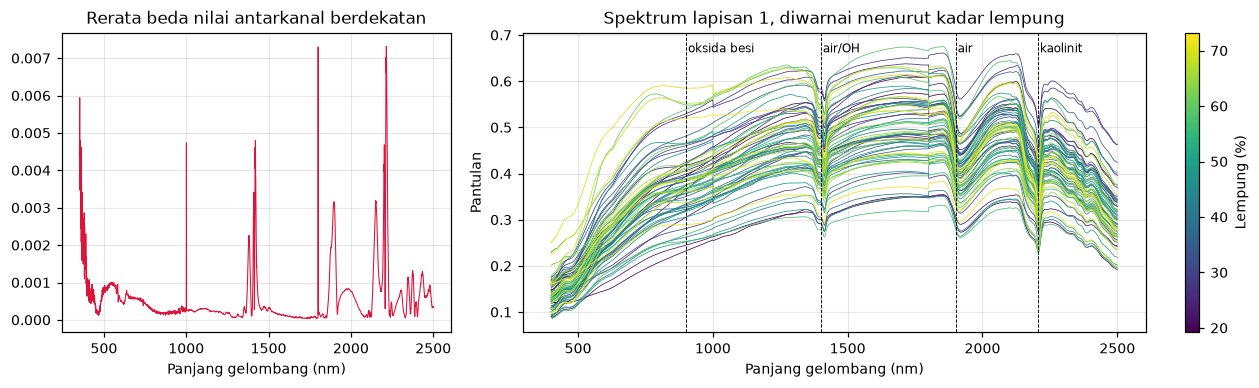

In [5]:
S = data_l1[kolom_spektrum].values
print('Beda antarkanal 350-399 nm :', round(np.abs(np.diff(S[:, panjang_gel < 400], axis=1)).mean(), 5))
print('Beda antarkanal 400-2500 nm:', round(np.abs(np.diff(S[:, panjang_gel >= 400], axis=1)).mean(), 5))
pilih = panjang_gel >= 400
wl = panjang_gel[pilih]
R = S[:, pilih]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={'width_ratios': [1, 2]})
ax[0].plot(panjang_gel[1:], np.abs(np.diff(S, axis=1)).mean(axis=0), color='crimson', lw=.7)
ax[0].set(title='Rerata beda nilai antarkanal berdekatan', xlabel='Panjang gelombang (nm)')
urut = np.argsort(data_l1['clay'].values)
warna = plt.cm.viridis(np.linspace(0, 1, len(urut)))
for w, i in zip(warna, urut):
    ax[1].plot(wl, R[i], color=w, lw=.5)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(data_l1['clay'].min(), data_l1['clay'].max()))
plt.colorbar(sm, ax=ax[1], label='Lempung (%)')
for pos, nama in [(900, 'oksida besi'), (1400, 'air/OH'), (1900, 'air'), (2205, 'kaolinit')]:
    ax[1].axvline(pos, color='k', lw=.6, ls='--'); ax[1].text(pos + 8, ax[1].get_ylim()[1] * .94, nama, fontsize=8)
ax[1].set(title='Spektrum lapisan 1, diwarnai menurut kadar lempung', xlabel='Panjang gelombang (nm)', ylabel='Pantulan')
plt.tight_layout(); plt.savefig('hasil/spektrum_lapisan1.png', dpi=150); plt.show()

Spektrum yang halus seharusnya hampir tidak berubah antarkanal yang berdekatan. Di bawah 400 nm nilainya melompat-lompat, yang menandakan derau (*noise*), sehingga pemodelan hanya memakai 400–2.500 nm. Lonjakan sempit di 1.000 nm dan 1.800 nm berada pada batas antardetektor alat.

## 4. Membaca fitur serapan

Lembah di sekitar 2.205 nm berasal dari kaolinit, mineral lempung yang umum pada tanah tropis yang telah lapuk lanjut (Modul 7). Sel berikut mengukur kedalaman serapan (*absorption depth*) itu dengan garis kontinum (*continuum*) sederhana antara 2.120 nm dan 2.250 nm, lalu membandingkannya dengan kadar lempung.

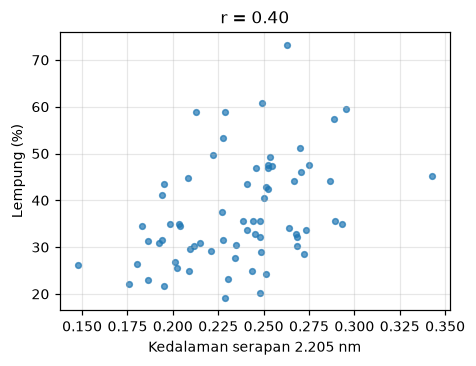

Korelasi kedalaman serapan dengan lempung: 0.4


In [6]:
def kedalaman_serapan(R, wl, kiri=2120, pusat=2205, kanan=2250):
    i, c, k = [np.argmin(np.abs(wl - v)) for v in (kiri, pusat, kanan)]
    kontinum = R[:, i] + (R[:, k] - R[:, i]) * (wl[c] - wl[i]) / (wl[k] - wl[i])
    return 1 - R[:, c] / kontinum

kedalaman = kedalaman_serapan(R, wl)
r_lempung = np.corrcoef(kedalaman, data_l1['clay'])[0, 1]
fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.scatter(kedalaman, data_l1['clay'], s=14, alpha=.7)
ax.set(xlabel='Kedalaman serapan 2.205 nm', ylabel='Lempung (%)', title=f'r = {r_lempung:.2f}')
plt.tight_layout(); plt.savefig('hasil/fitur_serapan.png', dpi=150); plt.show()
print('Korelasi kedalaman serapan dengan lempung:', round(r_lempung, 2))

## 5. Membagi data latih dan uji

Data dibagi sekali secara acak: 80% sebagai data latih (*training set*) dan 20% sebagai data uji (*test set*). Pembagian yang sama dipakai untuk semua praolah dan algoritme, sehingga perbandingannya adil. Data uji tidak disentuh sampai penilaian akhir.

In [7]:
latih, uji = train_test_split(np.arange(len(data_l1)), test_size=0.2, random_state=42)
print('Latih:', len(latih), 'sampel | Uji:', len(uji), 'sampel')

Latih: 55 sampel | Uji: 14 sampel


## 6. Praolah spektrum

Sebagian besar keragaman spektrum disebabkan oleh ukuran partikel dan hamburan (*scattering*), bukan komposisi kimia. Lima praolah dicoba:

1. **RAW**, yaitu pantulan apa adanya.
2. **SNV** (*Standard Normal Variate*), yaitu setiap spektrum dikurangi rata-ratanya lalu dibagi simpangan bakunya (Barnes et al., 1989).
3. **MSC** (*Multiplicative Scatter Correction*), yaitu setiap spektrum diregresikan terhadap spektrum acuan, lalu dikoreksi dengan potongan dan kemiringannya (Geladi et al., 1985). Spektrum acuan dihitung dari data latih saja.
4. **SG**, yaitu penghalusan Savitzky–Golay (*Savitzky–Golay smoothing*) dengan jendela 11 kanal (Savitzky & Golay, 1964).
5. **SG-FD**, yaitu turunan pertama (*first derivative*) Savitzky–Golay, yang menonjolkan posisi fitur serapan.

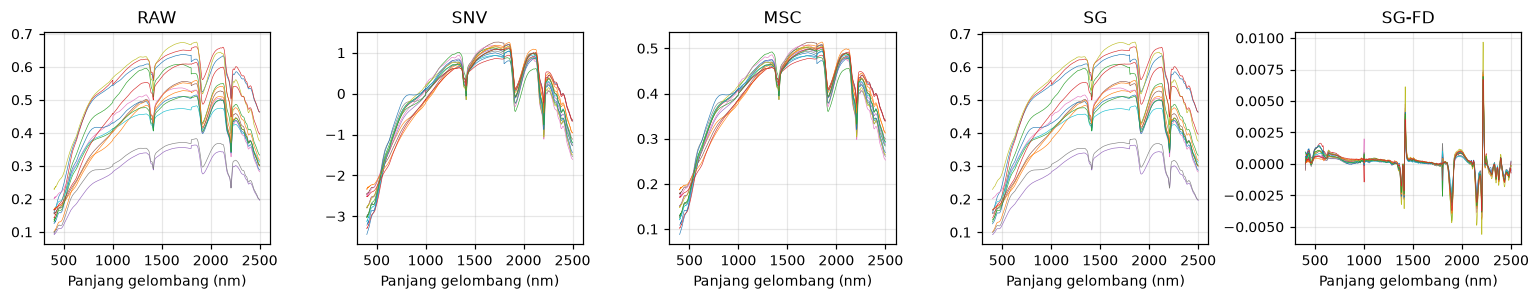

In [8]:
def snv(A):
    return (A - A.mean(axis=1, keepdims=True)) / A.std(axis=1, keepdims=True)

def msc(A, acuan):
    hasil = np.empty_like(A)
    for i, baris in enumerate(A):
        miring, potong = np.polyfit(acuan, baris, 1)
        hasil[i] = (baris - potong) / miring
    return hasil

def praolah(nama, A, acuan):
    if nama == 'RAW':
        return A
    if nama == 'SNV':
        return snv(A)
    if nama == 'MSC':
        return msc(A, acuan)
    return savgol_filter(A, window_length=11, polyorder=2, deriv=1 if nama == 'SG-FD' else 0, axis=1)

PRAOLAH = ['RAW', 'SNV', 'MSC', 'SG', 'SG-FD']
acuan_latih = R[latih].mean(axis=0)
fig, ax = plt.subplots(1, 5, figsize=(14, 2.8))
for a, nama in zip(ax, PRAOLAH):
    a.plot(wl, praolah(nama, R, acuan_latih)[::5].T, lw=.4)
    a.set(title=nama, xlabel='Panjang gelombang (nm)')
plt.tight_layout(); plt.savefig('hasil/praolah.png', dpi=150); plt.show()

## 7. Komposisi dan transformasi ILR

Bagaimana jika setiap fraksi dimodelkan sendiri-sendiri? Sel berikut melatih tiga model PLSR terpisah untuk lempung, debu, dan pasir, lalu menjumlahkan prediksinya.

In [9]:
Y = data_l1[FRAKSI].values / data_l1[FRAKSI].sum(axis=1).values[:, None] * 100     # tepat 100%
A_contoh = praolah('SG-FD', R, acuan_latih)
terpisah = np.column_stack([PLSRegression(10).fit(A_contoh[latih], Y[latih, j]).predict(A_contoh[uji]).ravel() for j in range(3)])
total = terpisah.sum(axis=1)
print(f'Tiga model terpisah (10 komponen, ilustrasi): jumlah prediksi {total.min():.1f}-{total.max():.1f}%')
print('Prediksi bernilai negatif:', int((terpisah < 0).sum()))

Tiga model terpisah (10 komponen, ilustrasi): jumlah prediksi 98.7-101.6%
Prediksi bernilai negatif: 0


Jumlahnya tidak lagi tepat 100%. Pada data ini selisihnya kecil, tetapi tidak ada yang menjaminnya. Pada tanah dengan salah satu fraksi yang sangat kecil, prediksi terpisah dapat bernilai negatif atau berjumlah jauh dari 100%. Transformasi ILR menjamin keduanya (Egozcue et al., 2003). Tiga persentase diubah menjadi dua koordinat log-rasio yang bebas bernilai berapa saja:

- ilr₁ = √(1/2) · ln(lempung / debu)
- ilr₂ = √(2/3) · ln(√(lempung · debu) / pasir)

Model memprediksi kedua koordinat itu, lalu hasilnya dikembalikan menjadi persentase. Hasil kebalikan ILR selalu positif dan selalu berjumlah 100%.

In [10]:
def ke_ilr(komposisi):
    c = komposisi / 100
    return np.column_stack([np.sqrt(1 / 2) * np.log(c[:, 0] / c[:, 1]),
                            np.sqrt(2 / 3) * np.log(np.sqrt(c[:, 0] * c[:, 1]) / c[:, 2])])

def dari_ilr(z):
    z = np.asarray(z, float).reshape(-1, 2)
    clr = np.column_stack([z[:, 0] / np.sqrt(2) + z[:, 1] / np.sqrt(6),
                           -z[:, 0] / np.sqrt(2) + z[:, 1] / np.sqrt(6),
                           -2 * z[:, 1] / np.sqrt(6)])
    x = np.exp(clr - clr.max(axis=1, keepdims=True))
    return x / x.sum(axis=1, keepdims=True) * 100

Z = ke_ilr(Y)
print('Kembali utuh setelah ILR dan kebalikannya:', np.allclose(dari_ilr(Z), Y))
pd.DataFrame(np.column_stack([Y, Z]), columns=['lempung', 'debu', 'pasir', 'ilr1', 'ilr2']).head().round(3)

Kembali utuh setelah ILR dan kebalikannya: True


,lempung,debu,pasir,ilr1,ilr2
0,26.16,8.00,65.84,0.838,-1.237
1,31.24,10.92,57.84,0.743,-0.932
2,30.88,11.64,57.48,0.690,-0.906
3,34.50,8.40,57.10,0.999,-0.988
4,22.88,5.64,71.48,0.990,-1.502


## 8. Melatih PLSR dan *random forest* pada setiap praolah

Dua algoritme dibandingkan. **PLSR** adalah alat baku kemometrika (*chemometrics*) yang meringkas ribuan kanal menjadi beberapa komponen laten (*latent variables*) (Wold et al., 2001). Jumlah komponennya dipilih dengan validasi silang (*cross-validation*) 5 lipatan (*fold*) pada data latih. ***Random forest*** menggabungkan banyak pohon keputusan (*decision trees*) (Breiman, 2001) dan dilatih dengan pengaturan yang sama untuk semua praolah.

Untuk setiap kombinasi, dihitung dua hal. **RMSE validasi silang** dihitung hanya dari data latih, dengan 5 lipatan yang diulang 3 kali, dan dipakai untuk memilih kombinasi. **Ukuran pada data uji** dihitung per fraksi:

1. **R** (*Pearson correlation coefficient*), yaitu korelasi Pearson antara prediksi dan nilai laboratorium.
2. **R²** (*coefficient of determination*), yaitu bagian keragaman yang dijelaskan terhadap garis 1:1, sama dengan MEC pada Modul 8. Nilainya negatif jika model lebih buruk daripada menebak rata-rata.
3. **RMSE** (*root mean square error*) dan **MAE** (*mean absolute error*), yaitu besar galat dalam poin persen.
4. **nRMSE** (*normalized RMSE*), yaitu RMSE dibagi jangkauan nilai uji, dalam persen.
5. **MAPE** (*mean absolute percentage error*), yaitu rata-rata galat relatif. Nilai ini membesar pada fraksi yang kadarnya kecil seperti debu.

In [11]:
def ukuran(y, p):
    rmse = np.sqrt(mean_squared_error(y, p))
    return {'R': pearsonr(y, p)[0], 'R2': r2_score(y, p), 'RMSE': rmse, 'nRMSE%': 100 * rmse / np.ptp(y),
            'MAE': mean_absolute_error(y, p), 'MAPE%': 100 * np.mean(np.abs((p - y) / y))}

def rmse_komposisi(y, p):
    return np.sqrt(((y - p) ** 2).mean())

LIPATAN = RepeatedKFold(n_splits=5, n_repeats=3, random_state=0)

def rmse_cv(model, A, Zl, Yl):
    """RMSE komposisi dari validasi silang 5 lipatan yang diulang 3 kali, hanya pada data latih."""
    galat = [(dari_ilr(clone(model).fit(A[a], Zl[a]).predict(A[b])) - Yl[b]) ** 2 for a, b in LIPATAN.split(A)]
    return np.sqrt(np.concatenate(galat).mean())

def pilih_komponen(A, Zl, Yl, kandidat=range(1, 16)):
    """Jumlah komponen PLSR dengan RMSE validasi silang terkecil, hanya dari data latih."""
    nilai = [rmse_cv(PLSRegression(k), A, Zl, Yl) for k in kandidat]
    return kandidat[int(np.argmin(nilai))], min(nilai), nilai

def hutan():
    return RandomForestRegressor(n_estimators=300, max_features=0.3, random_state=42, n_jobs=-1)

hasil, prediksi, ringkas, kurva_cv = [], {}, [], {}
for nama_p in PRAOLAH:
    A = praolah(nama_p, R, acuan_latih)
    k, cv_pls, kurva_cv[nama_p] = pilih_komponen(A[latih], Z[latih], Y[latih])
    cv_rf = rmse_cv(hutan(), A[latih], Z[latih], Y[latih])
    for nama_m, model, cv in [('PLSR', PLSRegression(k), cv_pls), ('Random forest', hutan(), cv_rf)]:
        P = dari_ilr(model.fit(A[latih], Z[latih]).predict(A[uji]))
        prediksi[(nama_p, nama_m)] = P
        ringkas.append({'Praolah': nama_p, 'Algoritma': nama_m, 'Komponen PLSR': k if nama_m == 'PLSR' else np.nan, 'RMSE validasi silang': cv})
        for j, f in enumerate(FRAKSI):
            hasil.append({'Praolah': nama_p, 'Algoritma': nama_m, 'Fraksi': f, **ukuran(Y[uji, j], P[:, j])})
metrik = pd.DataFrame(hasil)
metrik.to_csv('hasil/metrik_per_fraksi.csv', index=False)
tabel = metrik.pivot_table(index=['Praolah', 'Algoritma'], columns='Fraksi', values=['R2', 'RMSE'])
tabel.columns = [f'{u} {f}' for u, f in tabel.columns]
tabel = tabel[[f'{u} {f}' for u in ['R2', 'RMSE'] for f in FRAKSI]]
tabel = tabel.join(pd.DataFrame(ringkas).set_index(['Praolah', 'Algoritma']))
tabel.loc[[(p, m) for p in PRAOLAH for m in ['PLSR', 'Random forest']]].round(2)

R2 clay  R2 silt  R2 sand  RMSE clay  RMSE silt  \
Praolah Algoritma                                                        
RAW     PLSR              0.60    -0.36     0.44       8.97       7.89   
        Random forest     0.21    -0.14     0.21      12.61       7.23   
SNV     PLSR              0.54    -0.54     0.65       9.58       8.42   
        Random forest     0.70     0.03     0.59       7.73       6.68   
MSC     PLSR              0.68     0.18     0.76       8.03       6.14   
        Random forest     0.69     0.05     0.57       7.92       6.61   
SG      PLSR              0.60    -0.36     0.44       8.97       7.89   
        Random forest     0.22    -0.14     0.22      12.52       7.23   
SG-FD   PLSR              0.45    -0.17     0.29      10.55       7.34   
        Random forest     0.54     0.13     0.59       9.58       6.33   

                       RMSE sand  Komponen PLSR  RMSE validasi silang  
Praolah Algoritma                                                      
RAW     PLSR               12.22            2.0                  8.44  
        Random forest      14.57            NaN                  9.75  
SNV     PLSR                9.64            6.0                  8.36  
        Random forest      10.52            NaN                  8.63  
MSC     PLSR                8.09            5.0                  8.47  
        Random forest      10.77            NaN                  8.53  
SG      PLSR               12.22            2.0                  8.44  
        Random forest      14.51            NaN                  9.72  
SG-FD   PLSR               13.85            3.0                  8.42  
        Random forest      10.47            NaN                  8.86

**Cara membaca.** Kolom R2 dan RMSE berasal dari 14 sampel uji, sedangkan kolom terakhir dari validasi silang pada data latih. Perhatikan bahwa urutan kombinasi menurut data uji tidak selalu sama dengan urutan menurut validasi silang.

## 9. Memilih kombinasi tanpa mengintip data uji

Godaannya adalah memilih kombinasi dengan R² uji tertinggi, lalu melaporkan R² itu. Cara itu curang: data uji ikut dipakai untuk memilih (*data leakage*), sehingga angkanya tidak lagi menggambarkan sampel yang benar-benar baru. Kombinasi dipilih dari RMSE validasi silang data latih, lalu dinilai sekali pada data uji.

Kombinasi terpilih dari validasi silang: ('SNV', 'PLSR') | komponen PLSR untuk praolah ini: 6


,Praolah,Algoritma,Komponen PLSR,RMSE validasi silang
0,SNV,PLSR,6.0,8.36
1,SG-FD,PLSR,3.0,8.42
2,RAW,PLSR,2.0,8.44
3,SG,PLSR,2.0,8.44
4,MSC,PLSR,5.0,8.47
5,MSC,Random forest,NaN,8.53
6,SNV,Random forest,NaN,8.63
7,SG-FD,Random forest,NaN,8.86
8,SG,Random forest,NaN,9.72
9,RAW,Random forest,NaN,9.75


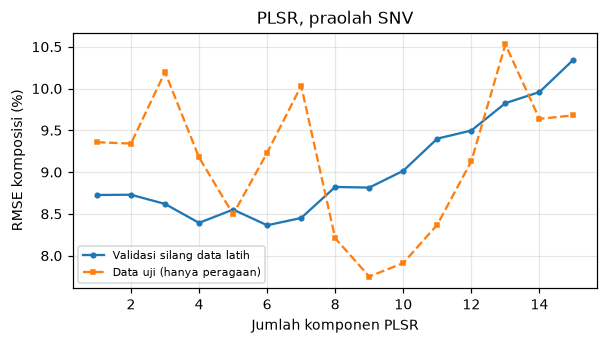

,R,R2,RMSE,nRMSE%,MAE,MAPE%
Fraksi,,,,,,
clay,0.75,0.54,9.58,18.08,6.78,17.72
silt,0.42,-0.54,8.42,45.84,7.13,70.67
sand,0.82,0.65,9.64,14.61,7.07,19.89


In [12]:
kv = pd.DataFrame(ringkas).sort_values('RMSE validasi silang')
TERPILIH = tuple(kv.iloc[0][['Praolah', 'Algoritma']])
K_PLSR = int(kv[(kv['Praolah'] == TERPILIH[0]) & (kv['Algoritma'] == 'PLSR')]['Komponen PLSR'].iloc[0])
print('Kombinasi terpilih dari validasi silang:', TERPILIH, '| komponen PLSR untuk praolah ini:', K_PLSR)
display(kv.round(2).reset_index(drop=True))

# kurva jumlah komponen PLSR pada praolah terpilih; garis data uji hanya untuk peragaan
A_t = praolah(TERPILIH[0], R, acuan_latih)
kurva_uji = [rmse_komposisi(Y[uji], dari_ilr(PLSRegression(k).fit(A_t[latih], Z[latih]).predict(A_t[uji]))) for k in range(1, 16)]
fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot(range(1, 16), kurva_cv[TERPILIH[0]], marker='o', ms=3, label='Validasi silang data latih')
ax.plot(range(1, 16), kurva_uji, marker='s', ms=3, ls='--', label='Data uji (hanya peragaan)')
ax.set(xlabel='Jumlah komponen PLSR', ylabel='RMSE komposisi (%)', title=f'PLSR, praolah {TERPILIH[0]}'); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig('hasil/pemilihan_komponen.png', dpi=150); plt.show()
metrik[(metrik['Praolah'] == TERPILIH[0]) & (metrik['Algoritma'] == TERPILIH[1])].set_index('Fraksi').drop(columns=['Praolah', 'Algoritma']).round(2)

Kedua garis pada gambar tidak selalu sejalan. Jika jumlah komponen dipilih dari garis data uji, angka uji akan tampak lebih baik, tetapi tidak lagi jujur, karena model sudah disesuaikan dengan 14 sampel yang seharusnya mewakili sampel baru.

## 10. Prediksi terhadap nilai laboratorium

Panel kiri sampai tengah membandingkan prediksi dengan nilai laboratorium untuk setiap fraksi. Panel kanan menempatkan setiap sampel uji pada segitiga tekstur (*soil texture triangle*): titik kosong adalah nilai laboratorium, titik isi adalah prediksi, dan garis menghubungkan keduanya.

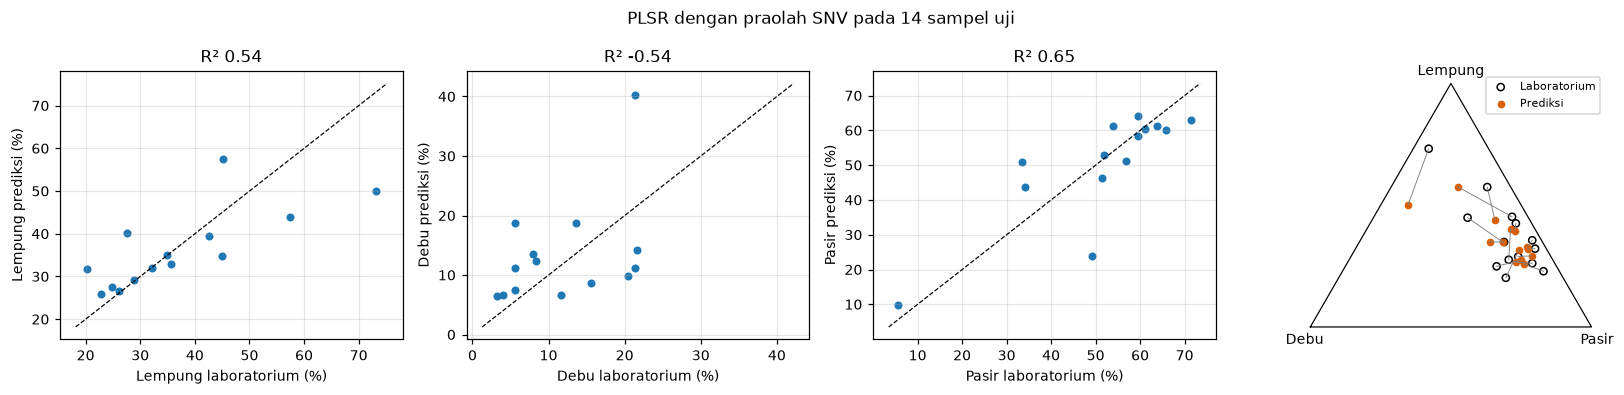

Jumlah setiap prediksi: 100.0 - 100.0 %


In [13]:
P = prediksi[TERPILIH]
nama_id = {'clay': 'Lempung', 'silt': 'Debu', 'sand': 'Pasir'}

def ke_segitiga(komposisi):
    l, p = komposisi[:, 0] / 100, komposisi[:, 2] / 100
    return p + l / 2, l * np.sqrt(3) / 2         # pasir ke kanan, lempung ke atas, debu ke kiri

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, (j, f) in zip(ax[:3], enumerate(FRAKSI)):
    a.scatter(Y[uji, j], P[:, j], s=18)
    b = [min(Y[uji, j].min(), P[:, j].min()) - 2, max(Y[uji, j].max(), P[:, j].max()) + 2]
    a.plot(b, b, 'k--', lw=.8)
    a.set(xlabel=f'{nama_id[f]} laboratorium (%)', ylabel=f'{nama_id[f]} prediksi (%)', title=f"R² {r2_score(Y[uji, j], P[:, j]):.2f}")
x0, y0 = ke_segitiga(Y[uji]); x1, y1 = ke_segitiga(P)
ax[3].plot([0, 1, .5, 0], [0, 0, np.sqrt(3) / 2, 0], color='k', lw=.8)
for i in range(len(uji)):
    ax[3].plot([x0[i], x1[i]], [y0[i], y1[i]], color='grey', lw=.6)
ax[3].scatter(x0, y0, s=22, facecolors='none', edgecolors='k', label='Laboratorium')
ax[3].scatter(x1, y1, s=16, color='#d95f02', label='Prediksi')
ax[3].text(.5, np.sqrt(3) / 2 + .03, 'Lempung', ha='center'); ax[3].text(-.02, -.06, 'Debu', ha='center'); ax[3].text(1.02, -.06, 'Pasir', ha='center')
ax[3].set_aspect('equal'); ax[3].axis('off'); ax[3].legend(fontsize=7, loc='upper right')
plt.suptitle(f'{TERPILIH[1]} dengan praolah {TERPILIH[0]} pada {len(uji)} sampel uji')
plt.tight_layout(); plt.savefig('hasil/prediksi_vs_laboratorium.png', dpi=150); plt.show()
print('Jumlah setiap prediksi:', np.round(P.sum(axis=1), 6).min(), '-', np.round(P.sum(axis=1), 6).max(), '%')

## 11. Seberapa stabil satu pembagian?

Dengan 14 sampel uji, angka di atas sangat bergantung pada sampel yang kebetulan terpilih. Sel berikut mengulang pembagian 80:20 sebanyak 20 kali dengan praolah terpilih dan pengaturan model yang sama.

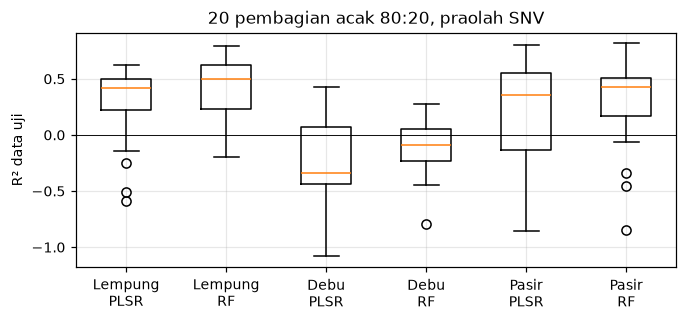

min   50%   max
Fraksi Algoritma                      
clay   PLSR          -0.59  0.42  0.62
       Random forest -0.20  0.49  0.79
silt   PLSR          -1.08 -0.34  0.43
       Random forest -0.79 -0.09  0.28
sand   PLSR          -0.86  0.36  0.80
       Random forest -0.85  0.43  0.82

In [14]:
ulang = []
for acak in range(20):
    a, b = train_test_split(np.arange(len(Y)), test_size=0.2, random_state=acak)
    Ai = praolah(TERPILIH[0], R, R[a].mean(axis=0))
    for nama_m, model in [('PLSR', PLSRegression(K_PLSR)), ('Random forest', hutan())]:
        Pu = dari_ilr(model.fit(Ai[a], Z[a]).predict(Ai[b]))
        ulang += [{'Algoritma': nama_m, 'Fraksi': f, 'R2': r2_score(Y[b, j], Pu[:, j])} for j, f in enumerate(FRAKSI)]
ulang = pd.DataFrame(ulang)
fig, ax = plt.subplots(figsize=(6.4, 3))
data_kotak = [ulang[(ulang['Algoritma'] == m) & (ulang['Fraksi'] == f)]['R2'] for f in FRAKSI for m in ['PLSR', 'Random forest']]
ax.boxplot(data_kotak)
ax.set_xticks(range(1, 7), [f'{nama_id[f]}\n{m}' for f in FRAKSI for m in ['PLSR', 'RF']])
ax.axhline(0, color='k', lw=.6); ax.set(ylabel='R² data uji', title=f'20 pembagian acak 80:20, praolah {TERPILIH[0]}')
plt.tight_layout(); plt.savefig('hasil/stabilitas_pembagian.png', dpi=150); plt.show()
ulang.groupby(['Fraksi', 'Algoritma'])['R2'].describe()[['min', '50%', 'max']].reindex(FRAKSI, level=0).round(2)

## 12. Wilayah spektrum mana yang dipakai model?

Kepentingan dihitung dengan permutasi (*permutation importance*) per fraksi: nilai satu wilayah spektrum pada data uji diacak, lalu diukur kenaikan MAE setiap fraksi. Kanal yang bersebelahan hampir identik, sehingga mengacak satu kanal saja hampir tidak berpengaruh karena informasinya masih ada di kanal tetangganya. Karena itu yang diacak adalah **jendela 20 nm** (*spectral window*), dengan 5 ulangan, dan satu prediksi dipakai untuk ketiga fraksi sekaligus. Perhitungan ini dibuat untuk praolah SG-FD pada kedua algoritme.

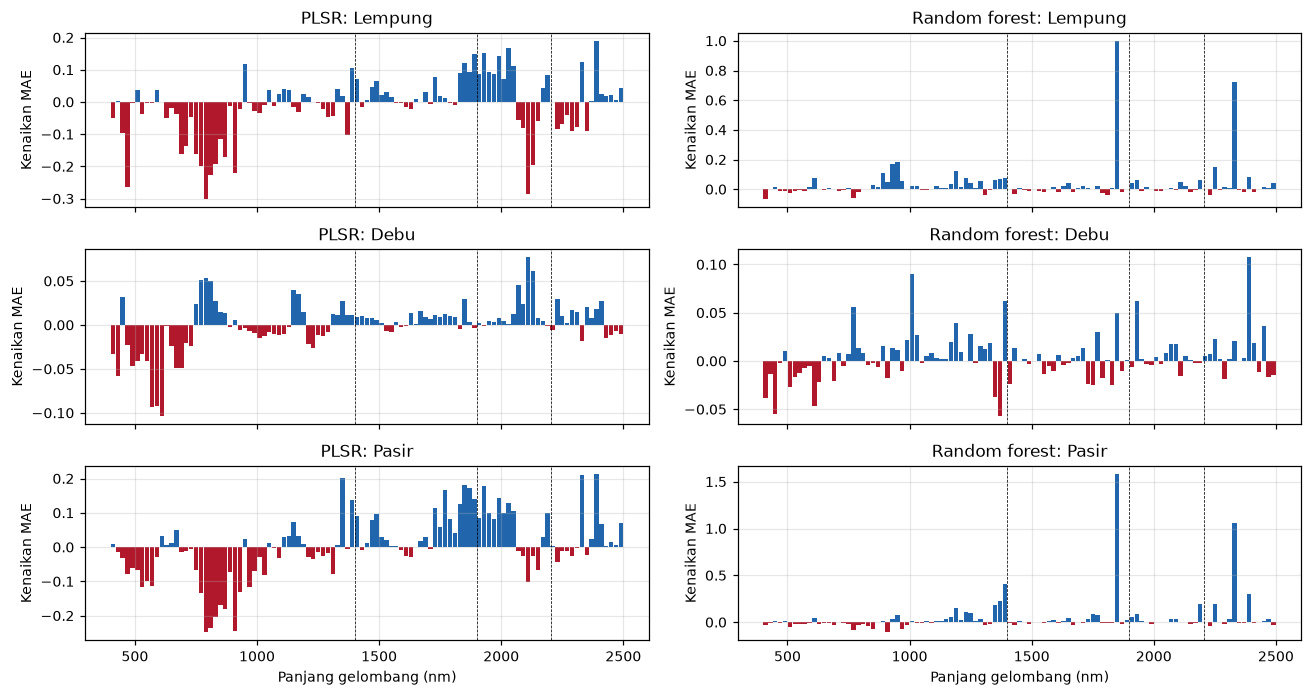

Jendela (nm)  Kenaikan MAE
Algoritma     Fraksi  Urutan                           
PLSR          Lempung 0         2380-2400         0.190
                      1         2020-2040         0.166
                      2         1920-1940         0.153
              Debu    0         2100-2120         0.077
                      1         2120-2140         0.061
                      2           780-800         0.054
              Pasir   0         2380-2400         0.214
                      1         2320-2340         0.211
                      2         1340-1360         0.202
Random forest Lempung 0         1840-1860         1.000
                      1         2320-2340         0.725
                      2           940-960         0.183
              Debu    0         2380-2400         0.107
                      1         1000-1020         0.090
                      2         1920-1940         0.063
              Pasir   0         1840-1860         1.583
                      1         2320-2340         1.057
                      2         1380-1400         0.410

In [15]:
LEBAR = 20
jendela = [(a, a + LEBAR) for a in range(400, 2500, LEBAR)]
indeks = [np.where((wl >= a) & (wl < b))[0] for a, b in jendela]

def kepentingan_jendela(model, A_uji, Y_uji, ulang=5, seed=0):
    rng = np.random.default_rng(seed)
    dasar = np.abs(dari_ilr(model.predict(A_uji)) - Y_uji).mean(axis=0)
    naik = np.zeros((len(indeks), 3))
    for i, ii in enumerate(indeks):
        for _ in range(ulang):
            Ap = A_uji.copy()
            Ap[:, ii] = A_uji[rng.permutation(len(A_uji))][:, ii]
            naik[i] += (np.abs(dari_ilr(model.predict(Ap)) - Y_uji).mean(axis=0) - dasar) / ulang
    return pd.DataFrame(naik, columns=FRAKSI, index=[f'{a}-{b}' for a, b in jendela])

A_fd = praolah('SG-FD', R, None)
k_fd = int(pd.DataFrame(ringkas).query("Praolah == 'SG-FD' and Algoritma == 'PLSR'")['Komponen PLSR'].iloc[0])
kepentingan = {}
for nama_m, model in [('PLSR', PLSRegression(k_fd)), ('Random forest', hutan())]:
    kepentingan[nama_m] = kepentingan_jendela(model.fit(A_fd[latih], Z[latih]), A_fd[uji], Y[uji])

tengah = [a + LEBAR / 2 for a, _ in jendela]
fig, ax = plt.subplots(3, 2, figsize=(12, 6.4), sharex=True)
for c, (nama_m, imp) in enumerate(kepentingan.items()):
    for r_, f in enumerate(FRAKSI):
        a = ax[r_, c]
        a.bar(tengah, imp[f], width=LEBAR * .9, color=np.where(imp[f] > 0, '#2166ac', '#b2182b'))
        for pos in (1400, 1900, 2205):
            a.axvline(pos, color='k', lw=.5, ls='--')
        a.set(title=f'{nama_m}: {nama_id[f]}', ylabel='Kenaikan MAE')
for a in ax[-1]:
    a.set_xlabel('Panjang gelombang (nm)')
plt.tight_layout(); plt.savefig('hasil/kepentingan_jendela.png', dpi=150); plt.show()

teratas = pd.concat({(m, nama_id[f]): imp[f].sort_values(ascending=False).head(10).reset_index().rename(columns={'index': 'Jendela (nm)', f: 'Kenaikan MAE'})
                     for m, imp in kepentingan.items() for f in FRAKSI}, names=['Algoritma', 'Fraksi', 'Urutan'])
teratas.to_csv('hasil/kepentingan_jendela_top10.csv')
teratas.groupby(level=[0, 1]).head(3).round(3)

Batang biru menandai jendela yang, bila diacak, menaikkan galat, sedangkan batang merah berarti galat justru turun. Hasil dari 14 sampel uji ini masih kasar, sehingga yang patut diperhatikan adalah wilayah yang konsisten, misalnya di sekitar serapan air dan hidroksil (1.400 dan 1.900 nm) atau kaolinit (2.205 nm), bukan urutan jendela satu per satu.

## 13. Memakai model untuk sampel tanah baru

Setelah model jadi, sampel tanah baru cukup diukur spektrumnya tanpa dianalisis di laboratorium. Ada lima langkah:

1. **Latih model akhir dan simpan**, yaitu model dilatih ulang dengan seluruh 69 sampel memakai kombinasi terpilih, lalu disimpan ke berkas bersama semua yang diperlukan untuk memakainya: nama praolah, spektrum acuan MSC, daftar panjang gelombang, dan ringkasan sebaran spektrum pustaka.
2. **Siapkan spektrum baru**, yaitu berkas CSV dengan kolom `sampel` dan `w350` sampai `w2500`, satu baris per sampel. Berkas `spektrum_sampel_baru.csv` adalah contohnya (*dummy*). Isinya 10 spektrum asli dari pustaka yang sama tanpa kolom laboratorium, yaitu dua sampel lapisan 1 yang memang tidak dianalisis dan delapan sampel lapisan 4 yang tidak dipakai melatih model.
3. **Prediksi**, yaitu spektrum baru diberi praolah yang **sama persis**, dimasukkan ke model, lalu hasilnya dikembalikan menjadi persentase.
4. **Periksa kemiripan dengan pustaka**, karena model hanya dapat dipercaya untuk spektrum yang mirip dengan spektrum yang dipakai melatihnya. Kemiripan diukur dengan jarak Mahalanobis (*Mahalanobis distance*) pada lima komponen utama spektrum pustaka (*principal component analysis*, PCA). Jarak itu dibagi jarak sampel pustaka yang terjauh, sehingga nilai di atas 1 berarti spektrum baru lebih asing daripada sampel pustaka mana pun.
5. **Uji sebagian sampel di laboratorium**, karena kemiripan spektrum tidak menjamin prediksi benar, seperti terlihat pada sel terakhir.

In [16]:
acuan_semua = R.mean(axis=0)
A_semua = praolah(TERPILIH[0], R, acuan_semua)
model_akhir = (PLSRegression(K_PLSR) if TERPILIH[1] == 'PLSR' else hutan()).fit(A_semua, Z)
pca = PCA(n_components=5).fit(A_semua)
skor = pca.transform(A_semua)
paket = {'model': model_akhir, 'praolah': TERPILIH[0], 'acuan': acuan_semua, 'panjang_gel': wl, 'pca': pca,
         'ambang': np.sqrt(((skor / np.sqrt(pca.explained_variance_)) ** 2).sum(axis=1)).max()}
joblib.dump(paket, 'hasil/model_tekstur_lapisan1.joblib')
print('Model disimpan:', TERPILIH, '| keragaman spektrum yang diringkas lima komponen utama:', round(pca.explained_variance_ratio_.sum(), 3))

Model disimpan: ('SNV', 'PLSR') | keragaman spektrum yang diringkas lima komponen utama: 0.977


Fungsi berikut memuat model tersimpan, memeriksa kelengkapan kolom spektrum, memberi praolah yang sama, memprediksi, lalu menghitung jarak ke pustaka. Untuk sampel Anda sendiri, cukup ganti nama berkas pada `pd.read_csv`. Model tersimpan dapat dipakai lagi di lain waktu tanpa melatih ulang: jalankan bagian 1, sel fungsi praolah (bagian 6) dan ILR (bagian 7), lalu sel ini.

In [17]:
def prediksi_tekstur(tabel, berkas_model='hasil/model_tekstur_lapisan1.joblib'):
    """Prediksi lempung, debu, dan pasir untuk spektrum baru dengan model tersimpan."""
    paket = joblib.load(berkas_model)
    kolom = [f'w{int(w)}' for w in paket['panjang_gel']]
    kurang = [k for k in kolom if k not in tabel.columns]
    if kurang:
        raise ValueError(f'{len(kurang)} kolom spektrum tidak ada, misalnya {kurang[:3]}')
    A = praolah(paket['praolah'], tabel[kolom].to_numpy(float), paket['acuan'])
    hasil = pd.DataFrame(dari_ilr(paket['model'].predict(A)).round(1), columns=['Lempung (%)', 'Debu (%)', 'Pasir (%)'])
    hasil.insert(0, 'Sampel', tabel['sampel'].values)
    skor = paket['pca'].transform(A)
    jarak = np.sqrt(((skor / np.sqrt(paket['pca'].explained_variance_)) ** 2).sum(axis=1)) / paket['ambang']
    hasil['Jarak ke pustaka'] = jarak.round(2)
    hasil['Mirip pustaka'] = np.where(jarak <= 1, 'ya', 'tidak')
    return hasil

sampel_baru = pd.read_csv('spektrum_sampel_baru.csv')        # ganti dengan berkas spektrum Anda
prediksi_baru = prediksi_tekstur(sampel_baru)
prediksi_baru.to_csv('hasil/prediksi_sampel_baru.csv', index=False)
prediksi_baru

,Sampel,Lempung (%),Debu (%),Pasir (%),Jarak ke pustaka,Mirip pustaka
0,S73 L1,23.9,11.9,64.2,0.44,ya
1,S45 L1,25.1,9.4,65.5,0.39,ya
2,S5 L4,56.0,10.9,33.1,0.69,ya
3,S15 L4,66.3,14.8,18.9,0.58,ya
4,S28 L4,60.3,7.9,31.8,0.67,ya
5,S33 L4,53.6,10.9,35.6,0.48,ya
6,S49 L4,64.0,23.0,13.0,0.92,ya
7,S51 L4,45.5,6.3,48.2,0.50,ya
8,S53 L4,40.5,4.4,55.1,0.54,ya
9,S61 L4,56.4,24.7,18.9,0.59,ya


**Seberapa jauh model ini berlaku untuk tanah lain?** Delapan sampel lapisan 4 dalam berkas contoh sebenarnya memiliki hasil laboratorium di pustaka, demikian pula semua sampel lapisan 2 sampai 4. Sel berikut memperlakukan lapisan-lapisan bawah itu sebagai sampel baru, lalu membandingkan prediksinya dengan hasil laboratorium. Bias adalah rata-rata selisih prediksi terhadap nilai laboratorium, sehingga nilai positif berarti prediksi cenderung terlalu tinggi.

In [18]:
uji_lain = []
for lap in (2, 3, 4):
    t = data[(data['lapisan'] == lap) & data[FRAKSI].notna().all(axis=1) & (data[FRAKSI] > 0).all(axis=1)]
    Yt = t[FRAKSI].values / t[FRAKSI].sum(axis=1).values[:, None] * 100
    h = prediksi_tekstur(t)
    Pt = h[['Lempung (%)', 'Debu (%)', 'Pasir (%)']].values
    baris_uji = {'Lapisan': lap, 'Sampel': len(t), 'Mirip pustaka (%)': 100 * (h['Mirip pustaka'] == 'ya').mean()}
    for j, f in enumerate(FRAKSI):
        baris_uji[f'RMSE {nama_id[f].lower()}'] = np.sqrt(((Pt[:, j] - Yt[:, j]) ** 2).mean())
        baris_uji[f'Bias {nama_id[f].lower()}'] = (Pt[:, j] - Yt[:, j]).mean()
    uji_lain.append(baris_uji)
uji_lain = pd.DataFrame(uji_lain).round(1)
uji_lain.to_csv('hasil/uji_lapisan_bawah.csv', index=False)
print(f'Seluruh notebook selesai dalam {time.time() - MULAI:.0f} detik.')
uji_lain

Seluruh notebook selesai dalam 93 detik.


,Lapisan,Sampel,Mirip pustaka (%),RMSE lempung,Bias lempung,RMSE debu,Bias debu,RMSE pasir,Bias pasir
0,2,69,100.0,6.0,0.2,4.3,0.4,7.6,-0.6
1,3,64,95.3,7.9,2.0,4.8,-0.0,9.2,-2.0
2,4,60,80.0,13.7,6.7,5.9,2.9,17.2,-9.5


Lapisan 2 tampak cukup baik, bahkan lebih baik daripada data uji lapisan 1 di bagian 9, karena lapisan 2 berasal dari profil yang lapisan 1-nya ikut melatih model. Pada lapisan yang lebih dalam, galat dan biasnya membesar. Pada lapisan 4, lempung cenderung diduga terlalu tinggi dan pasir terlalu rendah, padahal sebagian besar spektrumnya dinilai mirip dengan pustaka, dan kedelapan sampel lapisan 4 pada berkas contoh pun lolos pemeriksaan kemiripan. Pemeriksaan kemiripan membantu menyaring spektrum yang asing, tetapi tidak menjamin prediksi benar. Karena itu, setiap kali model dipakai untuk tanah dari kebun atau kedalaman lain, kirim sebagian sampel ke laboratorium. Bila prediksinya bias, tambahkan sampel setempat ke data kalibrasi. Modul 7 menyebut cara ini *spiking*, dan pendekatan rs-local menunjukkan bahwa 12–20 sampel lokal sudah dapat meningkatkan ketelitian dan kekokohan prediksi (England & Viscarra Rossel, 2018).

## Yang dibawa ke diskusi

1. Mengapa prediksi tekstur perlu dibuat sebagai komposisi, dan apa yang terjadi bila setiap fraksi dimodelkan sendiri?
2. Fraksi mana yang paling mudah dan paling sulit diduga dari spektrum, dan mengapa?
3. Seberapa jauh satu angka R² dari 14 sampel uji dapat dipercaya, dilihat dari 20 pembagian acak?
4. Wilayah spektrum mana yang dipakai model, dan apakah sesuai dengan fitur serapan pada Modul 7?
5. Bila model ini dipakai untuk sampel dari kebun Anda, berapa sampel yang perlu dikirim ke laboratorium untuk memeriksanya?